# 数据集与数据加载器

理想情况下，我们希望数据集代码与模型训练代码解耦，以获得更好的可读性和模块化。\
PyTorch提供了两个数据原语：torch.utils.data.DataLoader和torch.utils.data.Dataset，允许使用预加载的数据集和自己的数据。Dataset存储样本及其对应的标签，而DataLoader在Dataset周围包装一个可迭代对象，以便轻松访问样本。\
PyTorch领域库提供了许多预加载的数据集（例如FashionMNIST）。

### 加载数据集
我们使用以下参数加载FashionMNIST数据集：
- root: 是存储训练/测试数据的路径
- train: 指定是训练还是测试数据集
- download=True: 表示如果root处没有数据，则从互联网下载
- transform 和 target_transform: 指定特征和标签转换

In [1]:
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt

training_data = datasets.FashionMNIST(
    root="data", 
    train=True, 
    download=True, 
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

test_data = datasets.FashionMNIST(
    root="data", 
    train=False, 
    download=True, 
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

### 迭代和可视化数据集
我们可以想列表一样手动索引Datasets: training_data[index]。我们使用matplotlib来可视化我们训练中的一些样本

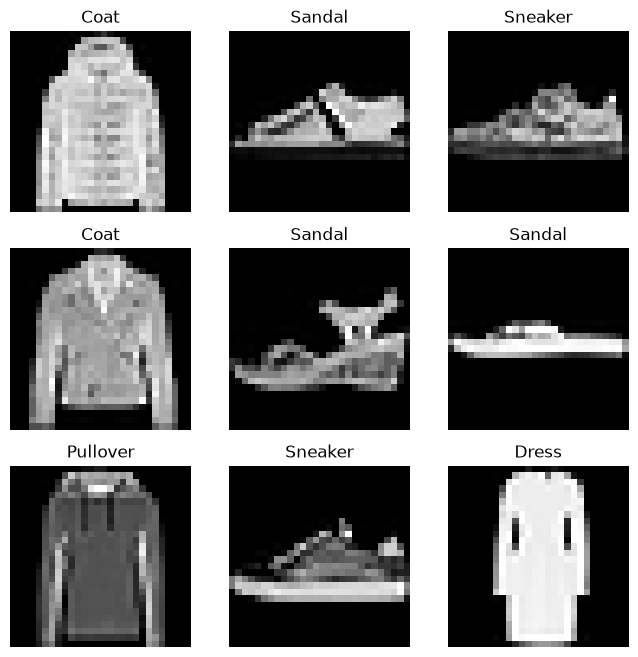

In [2]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

### 为文件创建自定义数据集
自定义Dataset类必须实现三个函数: \__init\__, \__len\__ 和 \__getitem\__。

In [3]:
import os
import pandas as pd
from torchvision.io import decode_image

class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = img_dir
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
        image = decode_image(img_path)
        label = self.img_labels.iloc[idx, 1]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

### \__init\__
在实例化Dataset对象时，\__init\__函数会运行一次。在这里初始化包含图像的目录，注释文件以及两个转换

labels.csv文件看起来像这样：\
\
tshirt1.jpg, 0\
tshirt2.jpg, 0\
......\
ankleboot999.jpg, 9


In [4]:
def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
    self.img_labels = pd.read_csv(annotations_file)
    self.img_dir = img_dir
    self.transform = transform
    self.target_transform = target_transform

### \__len\__
\__len\__函数返回我们数据集中的样本数量。

In [5]:
# 实例
def __len__(self):
    return len(self.img_labels)

### \__getitem\__
\__getitem\__函数在给定的索引idx处加载并返回数据集中的一个样本。它根据索引识别在磁盘上的位置，使用decode_image将其转换为张量，从self.img_labels中的csv数据索引相应的标签，对它们调用转换函数（如果适用），并返回包含张量图像和相应标签的元组。

In [6]:
def __getitem__(self, idx):
    img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
    image = decode_image(img_path)
    label = self.img_labels.iloc[idx, 1]
    if self.transform:
        image = self.transform(image)
    if self.target_transform:
        label = self.target_transform(label)
    return image, label

### 使用DataLoader准备训练数据
Dataset一次检索一个样本的数据集特征和标签。在训练模型时，我们通常希望以"小批量（minibatches）"的形式传递样本，在每个时期（epoch）重新打乱数据以减少模型过拟合，并使用Python的multiprocessing来加速数据检索。\
DataLoader是一个可迭代对象，它通过一个简单的API帮我们抽象了这种负责性。

In [7]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

### 遍历DataLoader
我们已经将该数据加载到DataLoader中，并可以根据需要遍历该数据集。下面的每次迭代都会返回一批train_features和train_labels（分别包含batch_size=64的特征和标签）。因为我们制定了shuffle=True，所以在我们遍历完所有批次后，数据会被打乱。

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


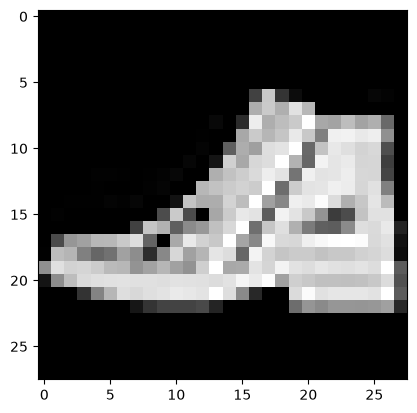

Label: 9


In [8]:
# Display image and label.
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze()
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")